## Week 10 作業：用 ResNet50V2 遷移學習辨識屋況

最常見的屋況問題是：裂縫、壁癌、鏽蝕這三種。

In [1]:
# 辨識類別 (請用英文、無空格)
category_en = "crack,efflorescence,ruststrain"

# 辨識類別的中文, 顯示時用的名稱
category_zh = "裂縫,壁癌,鏽蝕"

# APP 的名稱, 可自由更改
title = "地震房屋屋況辨識"

# APP 的說明, 可自由更改
description="請輸入一張房屋室內牆壁照片, 讓我告訴你房子有什麼屋況特徵!"

### 1. 安裝和讀入需要的套件

1. %matplotlib inline：用於指示 Python 將 matplotlib 的圖形直接嵌入到 notebook 中，使得在環境中生成的圖形可以直接在 notebook 中顯示。
2. import numpy as np：導入 NumPy 庫，並將其命名為 np，以便調用 NumPy 中的函數和類。
3. import pandas as pd：導入 pandas 庫，並將其命名為 pd，同樣，這樣可以使用 pd 作為 pandas 的別名，方便調用 pandas 中的函數和類。
4. import matplotlib.pyplot as plt：導入 matplotlib 中的 pyplot 模塊，並將其命名為 plt，這樣可以使用 plt 作為 pyplot 的別名，方便調用 pyplot 中的函數和類。



In [2]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
#從 TensorFlow 的 Keras API 中導入 ResNet50V2 模型。ResNet50V2 是一種基於殘差網絡的預訓練模型，通常用於圖像分類等任務。
from tensorflow.keras.applications import ResNet50V2
#從 TensorFlow 的 Keras API 中導入 Sequential 類，它是一種序貫模型，可以用於按照順序堆疊各種神經網絡層。
from tensorflow.keras.models import Sequential
#從 TensorFlow 的 Keras API 中導入 Dense 類，它是一種全連接層，用於在神經網絡中添加全連接層。
from tensorflow.keras.layers import Dense
#從 TensorFlow 的 Keras API 中導入 to_categorical 函數，用於將類別標籤轉換為 one-hot 編碼的形式。
from tensorflow.keras.utils import to_categorical
#從 TensorFlow 的 Keras API 中導入 preprocess_input 函數，它用於對圖像進行預處理，以適應 ResNet50V2 模型的輸入格式。
from tensorflow.keras.applications.resnet_v2 import preprocess_input
#從 TensorFlow 的 Keras API 中導入 load_img 和 img_to_array 函數，用於從文件加載圖像並將其轉換為 NumPy 數組的形式。
from tensorflow.keras.preprocessing.image import load_img, img_to_array

In [4]:
!pip install gradio

In [5]:
#Python 的一個內建庫，用於與操作系統進行交互。通常用於創建、刪除、移動文件和文件夾，或者在文件系統中獲取路徑信息等。
import os
#Python 的一個內建庫，用於壓縮和解壓縮文件。通常用於處理 zip 格式的壓縮文件。
import zipfile
#從 Python Imaging Library (PIL) 中導入 Image 類別，並將其別名為 Image。PIL 是一個 Python 库，用於圖像處理，包括讀取、編輯和保存圖像。
import PIL.Image as Image
#這是導入了 Gradio 庫，並將其別名為 gr。Gradio 是一個開源庫，用於構建交互式的機器學習應用程序，無需編寫任何前端代碼。
import gradio as gr

### 2. 創建資料夾

In [6]:
#將一個字符串 category_en 按照逗號 , 分割成多個子串，並將這些子串存儲到列表 categories 中。
categories = category_en.split(',')
#將另一個字符串 category_zh 按照逗號 , 分割成多個子串，並將這些子串存儲到列表 labels 中。
labels = category_zh.split(',')

In [7]:
# 計算了列表 categories 中元素的數量，辨識我們資料夾有幾類
N = len(categories)

以下是關於雲端資料夾的串接

In [8]:
base_dir = '/content/'

In [9]:
for category in categories:
    os.makedirs(f'./{category}', exist_ok=True)

In [10]:
!wget --no-check-certificate \
    https://github.com/Yunyuhu/concrete/raw/main/concrete.zip \
    -O /content/concrete.zip

--2024-05-08 06:24:36--  https://github.com/Yunyuhu/concrete/raw/main/concrete.zip
Resolving github.com (github.com)... 140.82.116.4
Connecting to github.com (github.com)|140.82.116.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/Yunyuhu/concrete/main/concrete.zip [following]
--2024-05-08 06:24:36--  https://raw.githubusercontent.com/Yunyuhu/concrete/main/concrete.zip
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 50630700 (48M) [application/zip]
Saving to: ‘/content/concrete.zip’

/content/concrete.z 100%[===================>]  48.29M   187MB/s    in 0.3s    

2024-05-08 06:24:36 (187 MB/s) - ‘/content/concrete.zip’ saved [50630700/50630700]



In [11]:
local_zip = '/content/concrete.zip'
zip_ref = zipfile.ZipFile(local_zip, 'r')
zip_ref.extractall('/content')
zip_ref.close()

確認資料是否串接正確，列出crack的資料夾照片確認資料。

In [12]:
thedir = base_dir + categories[0]
os.listdir(thedir)

['crack11.jpg',
 'crack02.jpg',
 'crack03.jpg',
 'crack13.jpg',
 'crack08.jpg',
 'crack01.jpg',
 'crack05.jpg',
 'crack06.jpg',
 'crack10.jpg',
 'crack09.jpg',
 'crack04.jpg',
 'crack12.jpg',
 'crack14.jpg',
 '.DS_Store',
 'crack07.jpg']

接下來，我們要將這三個資料夾底下的照片作成輸入 (data)、輸出 (target)。

因為Mac會有奇怪的檔案產生，所以在城市中加入if，僅判斷'.jpg', '.jpeg'的檔案。

In [13]:
data = []
target = []
for i in range(N):
    thedir = base_dir + categories[i]
    file_names = os.listdir(thedir)
    for fname in file_names:
      if fname.lower().endswith(('.jpg', '.jpeg')):
        img_path = thedir + '/' + fname
        img = load_img(img_path , target_size = (224,224))
        x = img_to_array(img)
        data.append(x)
        target.append(i)

In [14]:
data = np.array(data)

先預覽目前讀取的資料有多少，確認資料的編排。

In [15]:
data.shape

(42, 224, 224, 3)

挑一張照片確認一下內容。

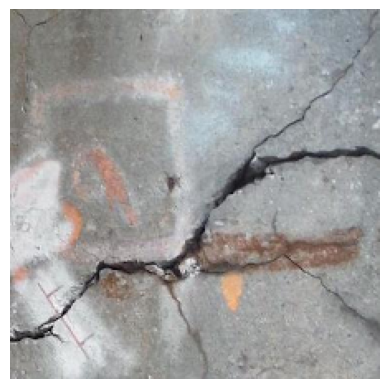

In [16]:
n = 1
plt.imshow(data[n]/255)
plt.axis('off');

以 ResNet 的預處理將圖像的整體亮度調整到相對一致的水平後，再確認一下內容。

In [17]:
x_train = preprocess_input(data)

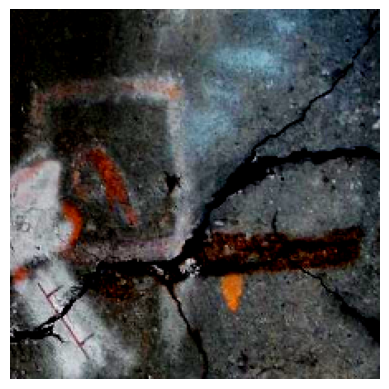

In [18]:
plt.imshow(x_train[n])
plt.axis('off');

這邊會跳出一個小小的警告，這是因為 ResNet 的預處理會將圖片的數據範圍常規化到 [-1, 1] 之間，與我們之前常規化到 [0, 1] 之間差一點點，所以畫圖時，matplotlib會自動作一些調整

每張圖的答案就是 0, 1, 2 其中一個數字。

In [19]:
target[n]

0

做 one-hot enconding。

In [20]:
y_train = to_categorical(target, N)

In [21]:
y_train[0]

array([1., 0., 0.], dtype=float32)

### 3. 用 ResNet50 打造我們的神經網路

ResNet50 是 2015 ImageNet 的冠軍, 我們用第二版來試試。

原本 ImageNet 是做了 1,000 個類別的圖形辨識。若用來辨識屋況特徵, 就是把最後一層 (通常就 1,000 個輸出的 dense 層) 砍掉 (`include_top=False`)。

再來我們可以把每個 filter 的結果做個大總合, 例如算每個 filter 計分板的總平均 (global average pooling), 並用 `tf.Keras` 工具，再下個參數即可 `pooling="avg"`)。

In [22]:
from tensorflow.keras.applications import ResNet50V2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [23]:
resnet = ResNet50V2(include_top=False, pooling="avg")

正式打造我們遷移學習版的函數學習機，只要再加入了最後一層．．．

In [24]:
model = Sequential()

In [25]:
model.add(resnet)

In [26]:
model.add(Dense(N, activation='softmax'))

原本 ResNet 的部份我們當然沒有重新訓練的意思。於是就設這邊不需要訓練。

In [27]:
resnet.trainable = False

#### 神經網路

In [28]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 resnet50v2 (Functional)     (None, 2048)              23564800  
                                                                 
 dense (Dense)               (None, 3)                 6147      
                                                                 
Total params: 23570947 (89.92 MB)
Trainable params: 6147 (24.01 KB)
Non-trainable params: 23564800 (89.89 MB)
_________________________________________________________________


#### 組裝我們的函數學習機

這裡我們用分類時非常標準的 `categorical_crossentropy`, 順便試試有名的 `adam` 學習法。

In [29]:
model.compile(loss='categorical_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])

### 4. 訓練 fit

In [ ]:
#model.fit(x_train, y_train, batch_size=10, epochs=10)

In [ ]:
#model.fit(x_train, y_train, batch_size=5, epochs=10)

In [30]:
model.fit(x_train, y_train, batch_size=8, epochs=8)

Epoch 1/8
6/6 [==============================] - 10s 828ms/step - loss: 1.1739 - accuracy: 0.3571
Epoch 2/8
6/6 [==============================] - 6s 959ms/step - loss: 0.6020 - accuracy: 0.8333
Epoch 3/8
6/6 [==============================] - 6s 827ms/step - loss: 0.4190 - accuracy: 0.9524
Epoch 4/8
6/6 [==============================] - 5s 817ms/step - loss: 0.2529 - accuracy: 0.9524
Epoch 5/8
6/6 [==============================] - 11s 2s/step - loss: 0.1692 - accuracy: 1.0000
Epoch 6/8
6/6 [==============================] - 5s 892ms/step - loss: 0.1264 - accuracy: 1.0000
Epoch 7/8
6/6 [==============================] - 6s 902ms/step - loss: 0.1001 - accuracy: 1.0000
Epoch 8/8
6/6 [==============================] - 5s 817ms/step - loss: 0.0822 - accuracy: 1.0000


### 5. 預測

用 model.evaluate 看一下模型表現

In [31]:
loss, acc = model.evaluate(x_train, y_train)
print(f"Loss: {loss}")
print(f"Accuracy: {acc}")

2/2 [==============================] - 8s 2s/step - loss: 0.0715 - accuracy: 1.0000
Loss: 0.07149617373943329
Accuracy: 1.0


In [32]:
y_predict = np.argmax(model.predict(x_train), -1)

2/2 [==============================] - 7s 1s/step


In [33]:
y_predict

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

可以比較一下資料訓練的正確答案。

In [34]:
target

[0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2]

### 6. 用 `gradio` 打造屋況特徵辨識 web app!

In [35]:
def resize_image(inp):
    # 將 NumPy array 轉換成 PIL Image 對象
    img = Image.fromarray(inp)

    # 將圖片調整為 224x224 像素
    img_resized = img.resize((224, 224), Image.Resampling.LANCZOS)

    # 將調整大小後的圖片轉換回 NumPy array
    img_array = np.array(img_resized)

    return img_array

In [36]:
def classify_image(inp):
    img_array = resize_image(inp)
    inp = img_array.reshape((1, 224, 224, 3))
    inp = preprocess_input(inp)
    prediction = model.predict(inp).flatten()
    return {labels[i]: float(prediction[i]) for i in range(3)}

In [37]:
image = gr.Image(label="房屋室內牆壁照片")
label = gr.Label(num_top_classes=N, label="AI辨識結果")

我們將屋況特徵數據庫中的圖片拿出來當作範例圖片讓使用者使用

In [38]:
sample_images = []
for i in range(N):
    thedir = base_dir + categories[i]
    for fname in os.listdir(thedir):
        sample_images.append(categories[i] + '/' + fname)

最後，將所有東西組裝在一起，就大功告成了！

In [ ]:
gr.Interface(fn=classify_image,
             inputs=image,
             outputs=label,
             title=title,
             description=description,
             examples=sample_images).launch(debug=True, share=True)